<a href="https://colab.research.google.com/github/Cherrymmu/AIFFEL_Online_Quest_Cherry/blob/main/%EB%94%A5%EB%9F%AC%EB%8B%9D%EC%9C%BC%EB%A1%9C%20%EC%8B%9C%EC%9E%91%ED%95%98%EB%8A%94%20%EC%BB%B4%ED%93%A8%ED%84%B0%20%EB%B9%84%EC%A0%84_CR7/10_Computer_Vision_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10-3. 프로젝트 2: Object Detection
---
1. Faster RCNN

논문: Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks
RCNN vs Fast R-CNN vs Faster R-CNN

2 stage detector(Region Proposal, Classification/Bounding Box Regression)
content img
[RCNN, Fast RCNN, Faster RCNN 비교]
https://wikidocs.net/148634

Faster RCNN의 구조
---

RCNN, Fast RCNN과 Faster RCNN의 가장 큰 차이점은 Selective Search를 Region Proposal Network(RPN) 로 바꾸었다는 것입니다.

RPN은 RoI가 될 후보군인 Anchor Box를 무수히 만듭니다. 그 후 Bounding Box Regression를 통해서 괜찮은 RoI를 딥러닝을 통해 학습하고 Classification을 통해 그것이 Object인지 아닌지를 판단합니다.

RPN을 통해 얻은 결과에 Object Classification을 통해서 해당 RoI에 있는 Object가 어떤 Class인지 구분하고, Bounding Box Regression을 실행합니다.

content img
[Faster RCNN의 구조]
https://towardsdatascience.com/faster-r-cnn-for-object-detection-a-technical-summary-474c5b857b46

코드 살펴보기
---
해당 코드는 텐서플로우 공식 홈페이지의 튜토리얼에서 제시된 코드를 활용했습니다.

먼저 필요한 라이브러리를 불러옵니다.

In [2]:
# Tensorflow와 Tensoflow Hub에 있는 이미 학습된 모델을 활용하기 위한 모듈
import tensorflow as tf
import tensorflow_hub as hub

# 이미지를 다운로드하는 데에 사용하는 모듈
import matplotlib.pyplot as plt
import tempfile
from six.moves.urllib.request import urlopen
from six import BytesIO

# 이미지에 선과 폰트를 넣기 위한 모듈
import numpy as np
from PIL import Image
from PIL import ImageColor
from PIL import ImageDraw
from PIL import ImageFont
from PIL import ImageOps

# Detection하는 데에 소요된 시간을 점검하기 위한 모듈
import time

이미지를 시각화하는 함수를 만들어 둡니다.

In [3]:

def display_image(image):
  fig = plt.figure(figsize=(20, 15))
  plt.grid(False)
  plt.imshow(image)

원하는 이미지를 다운로드하고 정해진 가로, 세로 길이에 맞게 이미지를 resizing하는 함수를 만들어둡니다.

In [4]:
def download_and_resize_image(url, new_width=256, new_height=256, display=False):

  _, filename = tempfile.mkstemp(suffix="/content/Torneo_beach_handball.jpg")
  response = urlopen(url)
  image_data = response.read()
  image_data = BytesIO(image_data)  # 이미지 읽기
  pil_image = Image.open(image_data)
  pil_image = ImageOps.fit(pil_image, (new_width, new_height), Image.ANTIALIAS) # 이미지 조정
  pil_image_rgb = pil_image.convert("RGB") #RBG로 변환
  pil_image_rgb.save(filename, format="JPG", quality=90) # 이미지 저장
  print("Image downloaded to %s." % filename)
  if display:
    display_image(pil_image)
  return filename

Bounding Box를 만드는 함수를 만듭니다.

In [5]:
def draw_bounding_box_on_image(image,
                               ymin, xmin, ymax, xmax,
                               color,
                               font,
                               thickness=4,
                               display_str_list=()):

  draw = ImageDraw.Draw(image)
  im_width, im_height = image.size
  (left, right, top, bottom) = (xmin * im_width, xmax * im_width,
                                ymin * im_height, ymax * im_height)

# BBox 테두리 그리기
  draw.line([(left, top), (left, bottom), (right, bottom), (right, top),
             (left, top)],
            width=thickness,
            fill=color)

  display_str_heights = [font.getsize(ds)[1] for ds in display_str_list]

  total_display_str_height = (1 + 2 * 0.05) * sum(display_str_heights)

  if top > total_display_str_height:
    text_bottom = top
  else:
    text_bottom = top + total_display_str_height

  for display_str in display_str_list[::-1]:
    text_width, text_height = font.getsize(display_str)
    margin = np.ceil(0.05 * text_height)
    draw.rectangle([(left, text_bottom - text_height - 2 * margin),
                    (left + text_width, text_bottom)],
                   fill=color)
    draw.text((left + margin, text_bottom - text_height - margin),
              display_str,
              fill="black",
              font=font)
    text_bottom -= text_height - 2 * margin

이미지 위에 class 이름과 score를 나타내는 함수도 만듭니다.






In [6]:
# BBox 그리기
def draw_boxes(image, boxes, class_names, scores, max_boxes=10, min_score=0.1):
  colors = list(ImageColor.colormap.values())

  try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/liberation/LiberationSansNarrow-Regular.ttf",
                              25)
  except IOError:
    print("Font not found, using default font.")
    font = ImageFont.load_default()

# BBox 그리기 적용
  for i in range(min(boxes.shape[0], max_boxes)):
    if scores[i] >= min_score:
      ymin, xmin, ymax, xmax = tuple(boxes[i])  # 박스 좌표값
      display_str = "{}: {}%".format(class_names[i].decode("ascii"),
                                     int(100 * scores[i]))
      color = colors[hash(class_names[i]) % len(colors)]
      image_pil = Image.fromarray(np.uint8(image)).convert("RGB")
      draw_bounding_box_on_image(
          image_pil,
          ymin,
          xmin,
          ymax,
          xmax,
          color,
          font,
          display_str_list=[display_str])
      np.copyto(image, np.array(image_pil))
  return image

이미지를 불러옵니다.

원하는 이미지를 불러오고, 가로와 세로를 변경해 보는 실험을 진행해 보세요.






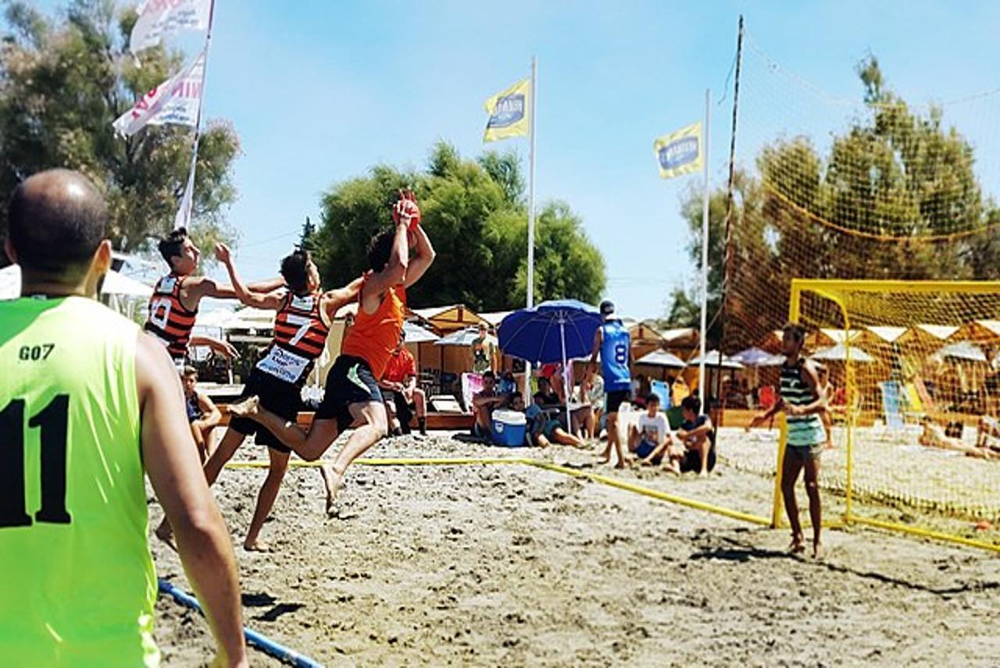

In [10]:
from PIL import Image
from IPython.display import display

# 이미지 파일 경로
file_path = '/content/Torneo_beach_handball.jpg'  # 이미지 파일의 경로를 지정하세요.

# 이미지 열기
image = Image.open(file_path)

# 새로운 크기 지정
new_width = 1280
new_height = 856

# 이미지 크기 조절
resized_image = image.resize((new_width, new_height))

# 조절된 이미지 보기 (옵션)
# resized_image.show()
display(resized_image)

# 조절된 이미지 저장 (옵션)
resized_image.save('/content/Torneo_beach_handball.jpg')

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
module_handle = "https://tfhub.dev/google/faster_rcnn/openimages_v4/inception_resnet_v2/1"

detector = hub.load(module_handle).signatures['default'] # detector에 사용할 모듈 저장

In [13]:
def load_img(path):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  return img

file_path = '/content/Torneo_beach_handball.jpg'

# 이미지 불러오기
img = load_img(file_path)

# 이미지 크기 조절
resized_img = tf.image.resize(img, [new_height, new_width])

In [14]:
def run_detector(detector, path):
  img = load_img(path)

  converted_img  = tf.image.convert_image_dtype(img, tf.float32)[tf.newaxis, ...]

# 소요시간 측정
  start_time = time.time()
  result = detector(converted_img)
  end_time = time.time()

  result = {key:value.numpy() for key,value in result.items()}

# 이미지 추론 개수와 추론 시간 출력
  print("Found %d objects." % len(result["detection_scores"]))
  print("Inference time: ", end_time-start_time)

# 이미지 내 박스로 entity, scores를 추가하여 출력
  image_with_boxes = draw_boxes(
      img.numpy(), result["detection_boxes"],
      result["detection_class_entities"], result["detection_scores"])

  display_image(image_with_boxes)

Found 100 objects.
Inference time:  120.17297148704529


<ipython-input-5-8b156eaed91c>:19: DeprecationWarning: getsize is deprecated and will be removed in Pillow 10 (2023-07-01). Use getbbox or getlength instead.
  display_str_heights = [font.getsize(ds)[1] for ds in display_str_list]
<ipython-input-5-8b156eaed91c>:29: DeprecationWarning: getsize is deprecated and will be removed in Pillow 10 (2023-07-01). Use getbbox or getlength instead.
  text_width, text_height = font.getsize(display_str)


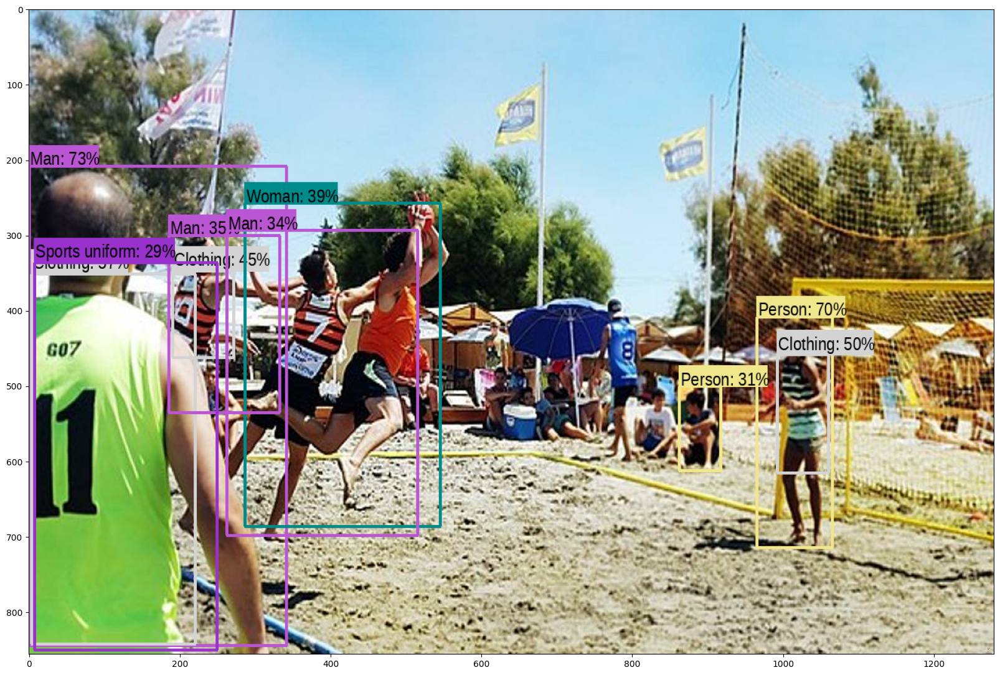

In [15]:
run_detector(detector, file_path)

문제 2-1. 다른 이미지 테스트해보기
---
원하는 이미지를 불러와 결과를 확인해 봅시다.

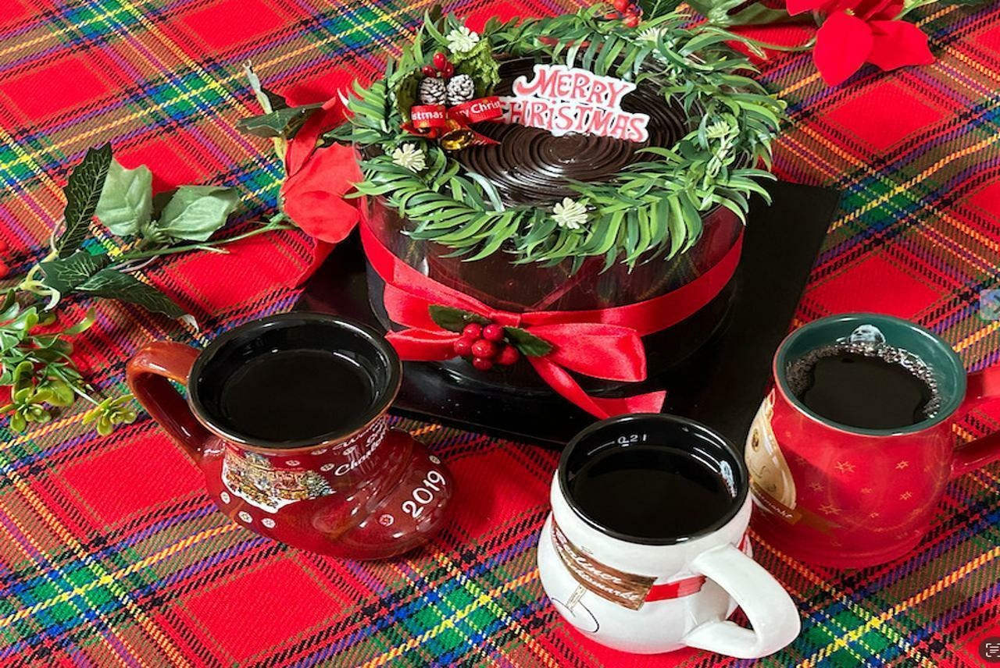

In [20]:
# 이미지 불러오기
from PIL import Image
from IPython.display import display

# 이미지 파일 경로
new_file_path = '/content/christmas.jpg'  # 이미지 파일의 경로를 지정하세요.

# 이미지 열기
new_image = Image.open(new_file_path)

# 새로운 크기 지정
new_width = 1280
new_height = 856

# 이미지 크기 조절
resized_new_image = new_image.resize((new_width, new_height))

# 조절된 이미지 보기 (옵션)
resized_new_image.show()

# 조절된 이미지 저장 (옵션)
resized_new_image.save('/content/christmas.jpg')

def load_img(path):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  return img

new_file_path = '/content/christmas.jpg'

# 이미지 불러오기
new_img = load_img(new_file_path)

# 이미지 크기 조절
resized_img = tf.image.resize(new_img, [new_height, new_width])

# 이미지로 변환
resized_img_pil = Image.fromarray(np.array(resized_img, dtype=np.uint8))

display(resized_img_pil)

Found 100 objects.
Inference time:  45.07969689369202


<ipython-input-5-8b156eaed91c>:19: DeprecationWarning: getsize is deprecated and will be removed in Pillow 10 (2023-07-01). Use getbbox or getlength instead.
  display_str_heights = [font.getsize(ds)[1] for ds in display_str_list]
<ipython-input-5-8b156eaed91c>:29: DeprecationWarning: getsize is deprecated and will be removed in Pillow 10 (2023-07-01). Use getbbox or getlength instead.
  text_width, text_height = font.getsize(display_str)


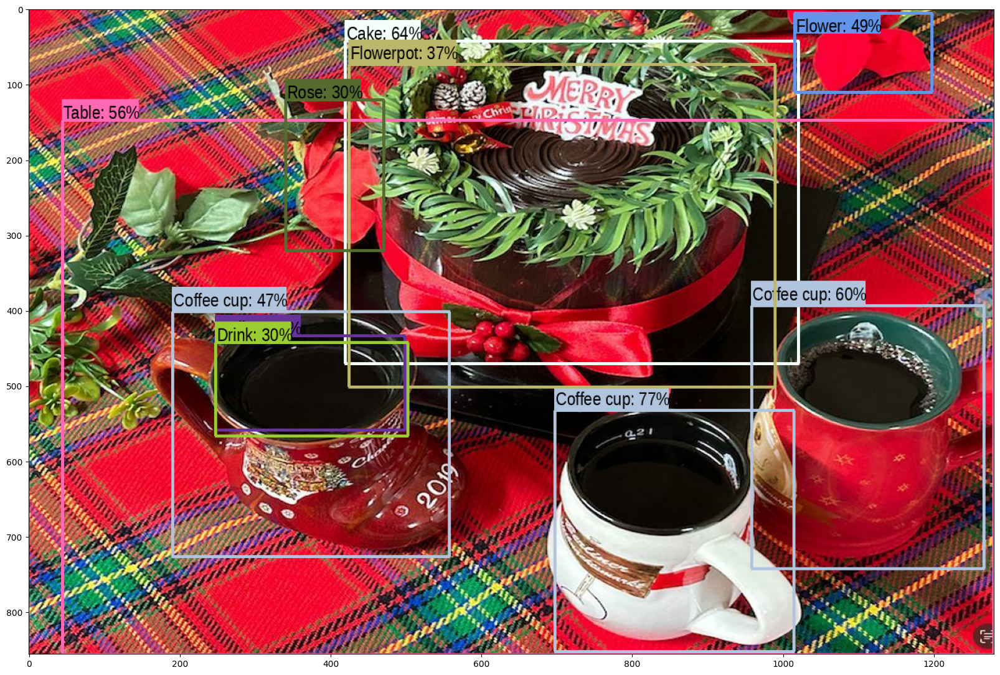

In [21]:
# 테스트
def run_detector(detector, path):
  new_img = load_img(path)

  converted_img  = tf.image.convert_image_dtype(new_img, tf.float32)[tf.newaxis, ...]

# 소요시간 측정
  start_time = time.time()
  result = detector(converted_img)
  end_time = time.time()

  result = {key:value.numpy() for key,value in result.items()}

# 이미지 추론 개수와 추론 시간 출력
  print("Found %d objects." % len(result["detection_scores"]))
  print("Inference time: ", end_time-start_time)

# 이미지 내 박스로 entity, scores를 추가하여 출력
  image_with_boxes = draw_boxes(
      new_img.numpy(), result["detection_boxes"],
      result["detection_class_entities"], result["detection_scores"])

  display_image(image_with_boxes)

run_detector(detector, new_file_path)

문제 2-2. 다양한 pre-trained model 테스트해보기
---
Faster RCNN 외에도 Object Detection을 할 수 있는 다양한 사전 학습 모델이 있습니다. tfhub을 탐색하여 사용할 수 있는 1개 이상의 모델을 불러와 결과를 테스트해보고, 그 결과를 비교해 보세요.

In [23]:
pip install keras_cv

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 601.9/601.9 kB 6.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 45.2 MB/s eta 0:00:00


In [26]:
# 문제 2-2. 모델 불러오기
import tensorflow as tf
import keras_cv
import time
from PIL import Image, ImageDraw, ImageFont
import numpy as np
from IPython.display import display as ipython_display

# 이미지 불러오는 함수
def load_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    return img

# 박스 그리기 및 이미지 표시 함수
def draw_boxes(image, boxes, class_entities, scores, max_boxes=10, min_score=0.1):
    colors = list(ImageColor.colormap.values())
    font = ImageFont.load_default()  # 기본 폰트 사용

    image_pil = Image.fromarray(np.uint8(image)).convert("RGB")
    draw = ImageDraw.Draw(image_pil)

    for i in range(min(len(boxes), max_boxes)):
        if scores[i] >= min_score:
            ymin, xmin, ymax, xmax = tuple(boxes[i])
            display_str = "{}: {}%".format(class_entities[i], int(100 * scores[i]))
            color = colors[i % len(colors)]

            (left, right, top, bottom) = (xmin * image_pil.width, xmax * image_pil.width,
                                          ymin * image_pil.height, ymax * image_pil.height)

            draw.rectangle(((left, top), (right, bottom)), outline=color)
            draw.text((left, top), display_str, fill=color, font=font)

    np.copyto(image, np.array(image_pil))

    return image

# 이미지 표시 함수
def display_image(image):
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)
    ipython_display(image)

# YOLO V8 모델 초기화
model = keras_cv.models.YOLOV8Backbone.from_preset("yolo_v8_l_backbone")

# 테스트
def run_detector(detector, path):
    new_img = load_img(path)
    converted_img = tf.image.convert_image_dtype(new_img, tf.float32)[tf.newaxis, ...]

    # 소요시간 측정
    start_time = time.time()
    result = detector(converted_img)
    end_time = time.time()

    # 모델의 출력 확인
    print("Model output keys:", result.keys())

    # YOLO V8 모델의 출력 형식에 맞게 결과 처리
    # 예시: result가 딕셔너리 형태인 경우
    if isinstance(result, dict) and 'detection_boxes' in result:
        boxes = result['detection_boxes']
        class_entities = result['detection_class_entities']
        scores = result['detection_scores']

        # 이미지 추론 개수와 추론 시간 출력
        print("Found %d objects." % len(scores))
        print("Inference time: ", end_time - start_time)

        # 이미지 내 박스로 entity, scores를 추가하여 출력
        image_with_boxes = draw_boxes(
            new_img.numpy(), boxes, class_entities, scores)

        display_image(image_with_boxes)
    else:
        print("Unexpected model output format")

# YOLO V8 모델을 detector로 사용
run_detector(model, new_file_path)

AttributeError: ignored

# 회고
---

Keep: 하루가 끝날 때까지 잡고 있는 인내심.
---

Problem: 욜로를 도전했지만 너무 어려웠다....
---

Try:다음에는 좀 더 시간이 있었으면 좋겠다.
---